In [1]:
import pandas as pd

product_sales = pd.read_csv(
    r"D:\Portfolio\retail-online-analysis\data\product_sales.csv",
    dtype={'InvoiceNo': 'string'}
)

product_sales['InvoiceDate'] = pd.to_datetime(product_sales['InvoiceDate'])
product_sales['CustomerID'] = product_sales['CustomerID'].astype('Int64')

product_sales['Revenue'] = product_sales['Quantity'] * product_sales['UnitPrice']

In [2]:
# 1. Best-selling products by revenue
best_selling_products_revenue = product_sales.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10)
print("Best-Selling Products by Revenue:", best_selling_products_revenue)

Best-Selling Products by Revenue: Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: Revenue, dtype: float64


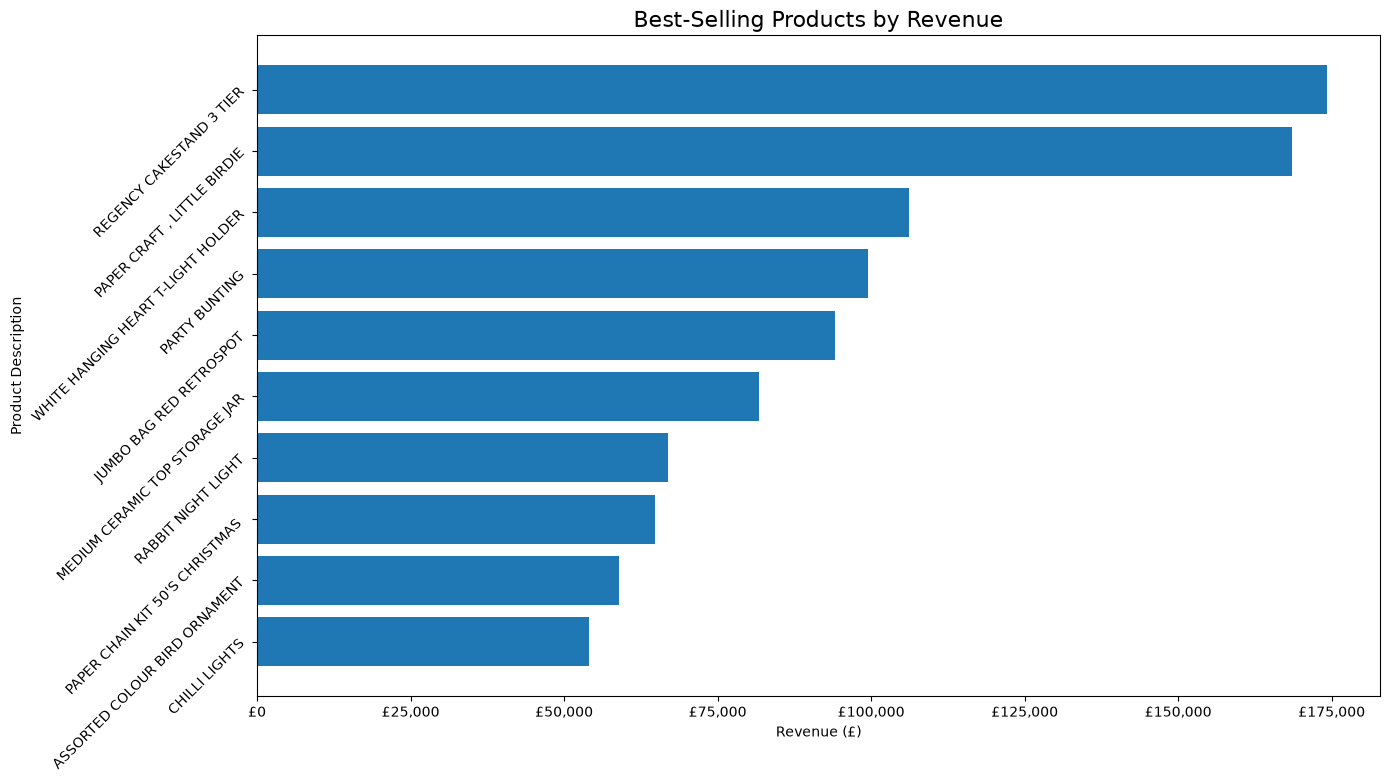

In [3]:
# 2. Visualize the best-selling products by revenue with a horizontal bar chart
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.figure(figsize=(14, 8))

plt.barh(
    best_selling_products_revenue.index,
    best_selling_products_revenue.values
)

plt.title('Best-Selling Products by Revenue', fontsize=16)
plt.xlabel('Revenue (£)')
plt.ylabel('Product Description')
plt.yticks(rotation=45, ha='right')
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter('£{x:,.0f}')
)

plt.tight_layout()
plt.show()

In [4]:
# 3. Best-selling products by quantity
best_selling_products_quantity = product_sales.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)
print("Best-Selling Products by Quantity:", best_selling_products_quantity)

Best-Selling Products by Quantity: Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


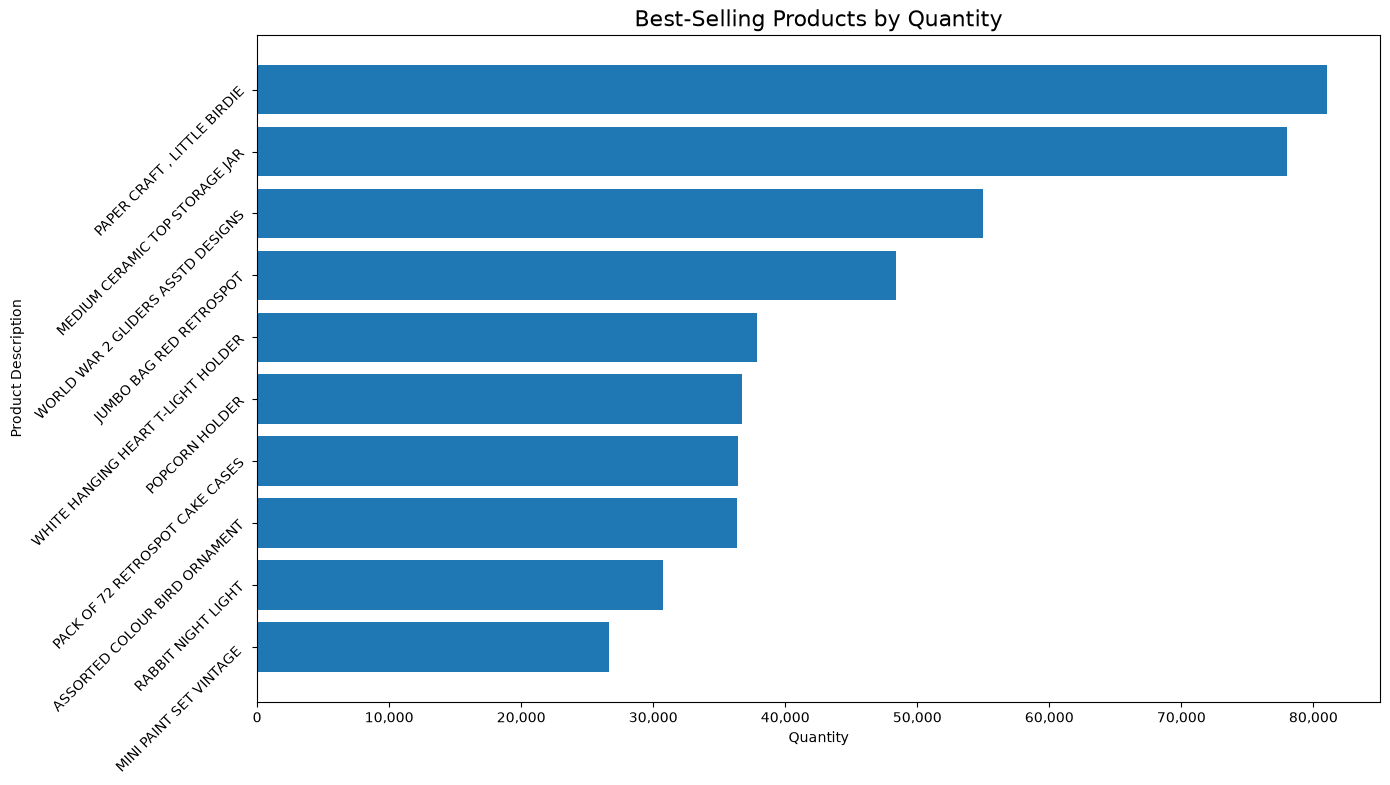

In [5]:
# 4. Visualize the best-selling products by quantity with a horizontal bar chart
plt.figure(figsize=(14, 8))

plt.barh(
    best_selling_products_quantity.index,
    best_selling_products_quantity.values
)

plt.title('Best-Selling Products by Quantity', fontsize=16)
plt.xlabel('Quantity')
plt.ylabel('Product Description')
plt.yticks(rotation=45, ha='right')
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter('{x:,.0f}')
)

plt.tight_layout()
plt.show()

In [6]:
# 5. Average revenue per product (revenue / quantity)

product_summary = (
    product_sales.groupby('Description')
    .agg(
        Total_Revenue=('Revenue', 'sum'),
        Total_Quantity=('Quantity', 'sum')
    )
)

product_summary['Average_Revenue_Per_Unit'] = (
    product_summary['Total_Revenue'] /
    product_summary['Total_Quantity']
)

product_summary = product_summary.sort_values(
    'Average_Revenue_Per_Unit',
    ascending=False
)

print(product_summary.head(10))

                                    Total_Revenue  Total_Quantity  \
Description                                                         
PICNIC BASKET WICKER 60 PIECES           39619.50              61   
RUSTIC  SEVENTEEN DRAWER SIDEBOARD        5415.00              35   
REGENCY MIRROR WITH SHUTTERS              1530.00              10   
VINTAGE BLUE KITCHEN CABINET              3685.00              26   
VINTAGE RED KITCHEN CABINET               8125.00              60   
CHEST NATURAL WOOD 20 DRAWERS             2745.00              24   
LOVE SEAT ANTIQUE WHITE METAL             6210.00              58   
SCHOOL DESK AND CHAIR                     1199.75              19   
DECORATIVE HANGING SHELVING UNIT           359.70               6   
VINTAGE POST OFFICE CABINET                607.65              11   

                                    Average_Revenue_Per_Unit  
Description                                                   
PICNIC BASKET WICKER 60 PIECES               

In [7]:
# 9. Display the products with the highest total revenue
top_revenue_products = product_summary.sort_values('Total_Revenue', ascending=False)

print(top_revenue_products.head(10))

                                    Total_Revenue  Total_Quantity  \
Description                                                         
REGENCY CAKESTAND 3 TIER                174156.54           13851   
PAPER CRAFT , LITTLE BIRDIE             168469.60           80995   
WHITE HANGING HEART T-LIGHT HOLDER      106236.72           37872   
PARTY BUNTING                            99445.23           18283   
JUMBO BAG RED RETROSPOT                  94159.81           48371   
MEDIUM CERAMIC TOP STORAGE JAR           81700.92           78033   
RABBIT NIGHT LIGHT                       66870.03           30739   
PAPER CHAIN KIT 50'S CHRISTMAS           64875.59           19329   
ASSORTED COLOUR BIRD ORNAMENT            58927.62           36362   
CHILLI LIGHTS                            54096.36           10302   

                                    Average_Revenue_Per_Unit  
Description                                                   
REGENCY CAKESTAND 3 TIER                     

# Summary

This notebook analyzes product performance using product_sales.csv, focusing on total revenue and quantity sold. The analysis revealed the following:
- **Highest-revenue product**: REGENCY CAKESTAND 3 TIER, generating £174,156.54 in revenue.
- **Highest-quantity product**: PAPER CRAFT , LITTLE BIRDIE, with 80,995 units sold.